# 02 — Experimentos de classificação

**Tema 4 — Default of Credit Card Clients (UCI 350).** Classe positiva: 1 (inadimplência no mês seguinte). As quatro famílias usam a mesma divisão treino/teste e as mesmas três dobras de validação no treino. A semente é 42.

Separamos uma dobra de cinco para o teste final (aproximadamente 20%). As divisões são **estratificadas e por grupos**: registros com os mesmos valores em todos os preditores ficam juntos, mesmo quando seus alvos diferem. Isso evita compartilhar perfis idênticos entre treino e validação/teste sem descartar observações. O identificador não participa dos grupos nem da modelagem. O teste não participa do ajuste de transformações, da escolha de parâmetros nem do limiar de decisão.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

SEMENTE = 42
raiz = Path.cwd() if Path("data").is_dir() else Path.cwd().parent
pasta_resultados = raiz / "results"
pasta_figuras = raiz / "figures"
for pasta in (pasta_resultados, pasta_figuras):
    pasta.mkdir(exist_ok=True)

base = pd.read_excel(raiz / "data" / "default_credit_card_clients.xls", header=1)
alvo = "default payment next month"
X = base.drop(columns=["ID", alvo])
y = base[alvo]
grupos = pd.util.hash_pandas_object(X, index=False)

divisao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
idx_treino, idx_teste = next(divisao.split(X, y, grupos))
X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
grupos_treino, grupos_teste = grupos.iloc[idx_treino], grupos.iloc[idx_teste]

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
dobras = list(cv.split(X_treino, y_treino, grupos_treino))
assert set(grupos_treino).isdisjoint(grupos_teste)
for idx_ajuste, idx_validacao in dobras:
    assert set(grupos_treino.iloc[idx_ajuste]).isdisjoint(grupos_treino.iloc[idx_validacao])

particoes = {"Treino": y_treino, "Teste": y_teste}
particoes.update({
    f"Validação {i} (no treino)": y_treino.iloc[idx_validacao]
    for i, (_, idx_validacao) in enumerate(dobras, 1)
})
display(pd.DataFrame.from_dict({
    nome: {"Registros": len(y_parte), "Classe 1": int(y_parte.sum()), "% classe 1": y_parte.mean() * 100}
    for nome, y_parte in particoes.items()
}, orient="index").round(2))

,Registros,Classe 1,% classe 1
Treino,24001,5336,22.23
Teste,5999,1300,21.67
Validação 1 (no treino),8005,1809,22.60
Validação 2 (no treino),7997,1747,21.85
Validação 3 (no treino),7999,1780,22.25


## Pré-processamento e modelos

- **Comum:** codificação one-hot de `SEX`, `EDUCATION`, `MARRIAGE` e dos seis status `PAY_*`; não é imposta distância ou ordem entre códigos não documentados. Os códigos observados são mantidos como categorias, e categorias não vistas no ajuste são ignoradas pelo codificador. Idade, limite e valores monetários são numéricos e mantêm os valores observados. A planilha não contém ausências; como salvaguarda, a pipeline pode imputar mediana nos numéricos e moda nos categóricos, sempre estimadas sobre os dados de ajuste.
- **Específico:** padronização (`StandardScaler`) nos numéricos para k-NN (distâncias) e regressão logística (escala da regularização). As árvores não precisam padronizar valores porque escolhem divisões por limiares. Todas as transformações são ajustadas dentro de cada pipeline/dobra. Não há reamostragem ou ajuste de limiar.
- **k-NN – visto em aula:** estima a classe pelos votos dos vizinhos; compara 15 e 45 vizinhos para variar a suavização da fronteira e testar padrões locais.
- **Árvore de decisão – vista em aula:** divide os registros por regras de atributo; compara profundidades máximas 4 e 8 para variar complexidade e representar interações.
- **Regressão logística – não encontrada nos slides:** modela a probabilidade por uma sigmoide de uma combinação linear dos atributos, útil como referência sem interações explícitas. Compara regularização L2 com `C=0.1` e `C=1.0`; quanto menor `C`, mais forte a penalização. Em linhas gerais: **iniciar coeficientes → minimizar perda logarítmica penalizada → aplicar sigmoide para obter a probabilidade → aplicar o limiar para obter a classe.**
- **Random Forest – não encontrada nos slides:** usa um conjunto de árvores para representar padrões não lineares, reduzindo a dependência de uma única árvore. Compara profundidades máximas 8 e 14, mantendo 80 árvores. Em linhas gerais: **para cada árvore, sortear uma amostra de treino com reposição → a cada nó, sortear candidatos a atributos e selecionar a melhor divisão entre eles → calcular probabilidades em cada árvore → tirar a média das probabilidades e obter a classe.**

A busca no material `conteudo/` não encontrou “regressão logística”, “logistic regression”, “Random Forest” ou “floresta aleatória”. **TODO (grupo):** confirmar a cobertura em aula e explicar com suas palavras o funcionamento e os parâmetros dos modelos.

In [2]:
categoricas = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
numericas = X.columns.difference(categoricas, sort=False).tolist()


def criar_pipeline(modelo, padronizar):
    passos_num = [("imputar", SimpleImputer(strategy="median"))]
    if padronizar:
        passos_num.append(("padronizar", StandardScaler()))
    categ = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preparo = ColumnTransformer([
        ("num", Pipeline(passos_num), numericas),
        ("cat", categ, categoricas),
    ])
    return Pipeline([("preparo", preparo), ("modelo", modelo)])


especificacoes = [
    ("k-NN", KNeighborsClassifier(), True, {"modelo__n_neighbors": [15, 45]}),
    ("Árvore de decisão", DecisionTreeClassifier(random_state=SEMENTE), False, {"modelo__max_depth": [4, 8]}),
    ("Regressão logística", LogisticRegression(max_iter=500, random_state=SEMENTE), True, {"modelo__C": [0.1, 1.0]}),
    ("Random Forest", RandomForestClassifier(n_estimators=80, n_jobs=1, random_state=SEMENTE), False,
     {"modelo__max_depth": [8, 14]}),
]

## Métricas e seleção

Tomando a inadimplência como classe positiva, VP = verdadeiro positivo, VN = verdadeiro negativo, FP = falso positivo e FN = falso negativo.

- **F1 (classe 1):** $F_1=\frac{2VP}{2VP+FP+FN}$. Combina precisão e sensibilidade da classe minoritária; se o denominador for zero, reporta 0.
- **Acurácia balanceada:** $\frac{1}{2}\left(\frac{VP}{VP+FN}+\frac{VN}{VN+FP}\right)$. Atribui peso igual à sensibilidade e à especificidade.
- **ROC-AUC:** $P(s_+>s_-)+\frac{1}{2}P(s_+=s_-)$, em que $s_+$ e $s_-$ são os escores de um exemplo positivo e um negativo. Avalia a ordenação sem fixar limiar.
- **Acurácia (referência):** $\frac{VP+VN}{VP+VN+FP+FN}$; isoladamente, pode ocultar baixo desempenho na classe minoritária.

Para cada família, as duas configurações são comparadas pela média de F1 na validação cruzada. Em empate, vale a primeira configuração listada. A configuração selecionada é reajustada com todo o treino, então avaliada no mesmo conjunto de teste para as quatro famílias. As métricas baseadas em classe e as matrizes usam a decisão padrão do estimador; a ROC-AUC usa a probabilidade da classe 1.

In [3]:
metricas = {
    "f1_classe_1": "f1",
    "roc_auc": "roc_auc",
    "acuracia_balanceada": "balanced_accuracy",
    "acuracia": "accuracy",
}
linhas_cv, linhas_teste, previsoes = [], [], {}


def formatar_parametros(parametros):
    return ", ".join(f"{chave.removeprefix('modelo__')}={valor}" for chave, valor in parametros.items())


with threadpool_limits(limits=1):
    for nome, modelo, padronizar, grade in especificacoes:
        busca = GridSearchCV(
            criar_pipeline(modelo, padronizar), grade, scoring=metricas, refit="f1_classe_1",
            cv=dobras, n_jobs=1, error_score="raise",
        )
        busca.fit(X_treino, y_treino)
        resultados = busca.cv_results_
        for i, parametros in enumerate(resultados["params"]):
            linha = {
                "modelo": nome,
                "parametros": formatar_parametros(parametros),
                "selecionado": i == busca.best_index_,
            }
            for metrica in metricas:
                linha[f"{metrica}_media"] = resultados[f"mean_test_{metrica}"][i]
                linha[f"{metrica}_dp"] = resultados[f"std_test_{metrica}"][i]
            linhas_cv.append(linha)

        modelo_final = busca.best_estimator_
        previsto = modelo_final.predict(X_teste)
        probabilidade = modelo_final.predict_proba(X_teste)[:, list(modelo_final.classes_).index(1)]
        previsoes[nome] = previsto
        linhas_teste.append({
            "modelo": nome,
            "parametros": formatar_parametros(busca.best_params_),
            "f1_classe_1": f1_score(y_teste, previsto, zero_division=0),
            "roc_auc": roc_auc_score(y_teste, probabilidade),
            "acuracia_balanceada": balanced_accuracy_score(y_teste, previsto),
            "acuracia": accuracy_score(y_teste, previsto),
        })

tabela_cv = pd.DataFrame(linhas_cv)
tabela_teste = pd.DataFrame(linhas_teste)
tabela_cv.to_csv(pasta_resultados / "validacao_cruzada.csv", index=False, float_format="%.6f")
tabela_teste.to_csv(pasta_resultados / "comparacao_teste.csv", index=False, float_format="%.6f")

display(tabela_cv.round(4))
display(tabela_teste.round(4))

,modelo,parametros,selecionado,f1_classe_1_media,f1_classe_1_dp,roc_auc_media,roc_auc_dp,acuracia_balanceada_media,acuracia_balanceada_dp,acuracia_media,acuracia_dp
0,k-NN,n_neighbors=15,True,0.4097,0.0070,0.7283,0.0022,0.6266,0.0035,0.8090,0.0037
1,k-NN,n_neighbors=45,False,0.3713,0.0044,0.7461,0.0014,0.6103,0.0021,0.8065,0.0046
2,Árvore de decisão,max_depth=4,False,0.4497,0.0081,0.7400,0.0035,0.6454,0.0037,0.8184,0.0025
3,Árvore de decisão,max_depth=8,True,0.4577,0.0102,0.7361,0.0070,0.6495,0.0056,0.8129,0.0047
4,Regressão logística,C=0.1,False,0.4686,0.0092,0.7680,0.0034,0.6547,0.0049,0.8203,0.0042
5,Regressão logística,C=1.0,True,0.4699,0.0088,0.7672,0.0031,0.6553,0.0046,0.8210,0.0043
6,Random Forest,max_depth=8,False,0.4414,0.0047,0.7762,0.0053,0.6414,0.0020,0.8179,0.0028
7,Random Forest,max_depth=14,True,0.4616,0.0034,0.7758,0.0054,0.6512,0.0018,0.8186,0.0041


,modelo,parametros,f1_classe_1,roc_auc,acuracia_balanceada,acuracia
0,k-NN,n_neighbors=15,0.4194,0.7384,0.6317,0.8145
1,Árvore de decisão,max_depth=8,0.4387,0.7432,0.6409,0.8183
2,Regressão logística,C=1.0,0.4573,0.7720,0.6500,0.8200
3,Random Forest,max_depth=14,0.4563,0.7825,0.6495,0.8205


## Matrizes de confusão no teste

Linhas = classe real; colunas = classe prevista. A classe 1 indica inadimplência.

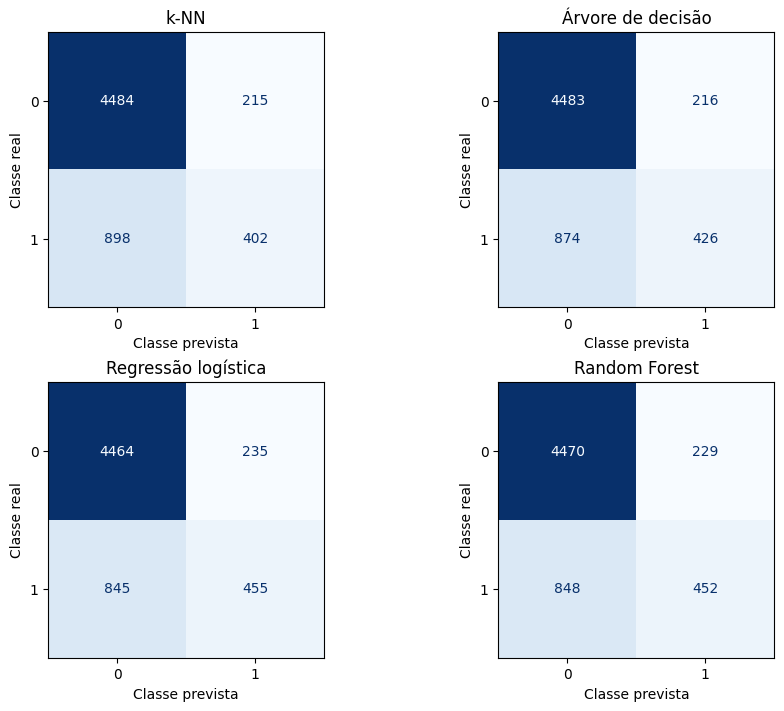

In [4]:
fig, eixos = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
for (nome, previsto), ax in zip(previsoes.items(), eixos.flat):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, previsto, labels=[0, 1], values_format="d", colorbar=False, cmap="Blues", ax=ax,
    )
    ax.set(title=nome, xlabel="Classe prevista", ylabel="Classe real")
fig.savefig(pasta_figuras / "matrizes_confusao.png", dpi=150)
plt.show()

## Discussão (preenchimento pelo grupo)

**TODO (grupo):** discutir diferenças entre métricas e configurações, comparar os tipos de erro, avaliar o papel do desbalanceamento e as limitações do experimento, e justificar a recomendação para o problema. Esta seção não contém uma interpretação automatizada dos resultados.